# 04 Small CNN trained from scratch: RGB versus 13 bands

**Purpose.** Train a convolutional neural network from scratch on RGB (3 channels) and on all 13 bands, with the same split, preprocessing, augmentation, settings and seeds. The only difference between the two inputs is the number of channels in the first layer, so a difference in the results comes from the bands.

**Functions.** `src/piece_of_crop/cnn.py` (`SmallCNN`), `train.py` (`seed_all`, `train_model`, `predict`, `predictions_table`) and `data.py` (`make_loaders`). The same training loop is used for the ResNet in notebook 05.

**Reads.** `results/split.csv`, `results/band_stats.csv` and the patch cache `data/eurosat_cache.npy`.

**Saves.** `results/cnn_results.csv`, `results/cnn_history.csv`, six test prediction files `results/predictions/cnn_<input>_seed<n>.csv`, the training curves `results/figures/cnn_<input>_training.png` and the trained weights in `models/` (not in Git; notebook 07 uses them).

## 1. Setup and shared data from notebook 02

All functions come from the installed `piece_of_crop` package. On a Mac the network trains on the GPU through MPS if PyTorch supports it, otherwise on the CPU.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import  torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, f1_score
from IPython.display import  display

from piece_of_crop import CLASS_NAMES,read_split, get_cache, make_loaders
from piece_of_crop import SmallCNN, seed_all, train_model, predict, predictions_table

# hyperparamters
SEEDS = (0,1,2)
BATCH_SIZE=128
EPOCHS = 30  # fixed, the cosine schedule runs over all of them
LEARNING_RATE= 1e-3

WEIGHT_DECAY=  1e-4


project_root= Path.cwd().parents[0]
data_dir = project_root/ "data" /'EuroSAT_MS'
results_dir = project_root/"results"
figures_dir= results_dir /"figures"
predictions_dir  = results_dir / "predictions"
models_dir=project_root/ "models"
#create the output folders if they dont excist
folders = [results_dir,figures_dir,predictions_dir , models_dir]
for folder in folders :
    folder.mkdir(parents = True , exist_ok=True)

split = read_split( results_dir /  "split.csv")
#print(split.head())
band_stats=pd.read_csv(results_dir/"band_stats.csv" )
cache = get_cache(split,data_dir , project_root / "data"/ "eurosat_cache.npy")

# check so labels goes from 0 to 9
label_ids =np.arange(len( CLASS_NAMES ))
assert np.array_equal(np.sort( split["label"].unique()),label_ids) , "Expected labels 0..9 , something wrong w the split"
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print ("Project root:", project_root)
print("Device:",device)
print('Patches:' , split["split"].value_counts().to_dict( ))
print( "Cache shape:",cache.shape)

Project root: /Users/estellearnander/sem5/AI/piece_of_crop
Device: mps
Patches: {'train': 19159, 'val': 3870, 'test': 3854, 'buffer': 117}
Cache shape: (27000, 13, 64, 64)


## 2. The network

We use the CNN of the course notebook (CNN_Class_Competition_2_Food_Classification_Explained.pdf, section 2) unchanged except for the number of input channels: three blocks of a 3 x 3 convolution, BatchNorm and ReLU with 32, 64 and 128 filters, with 2 x 2 max pooling after the first two blocks and global average pooling after the third, then one linear layer with 10 outputs.

- **Convolutions** slide a small filter over the patch, so the same pattern is recognised anywhere in it (lecture_8_DL_for_CV_1_compressed.pdf, slide 27). With `padding=1` the size stays the same, and each max pooling halves it: 64 x 64 becomes 32 x 32 and then 16 x 16.
- **BatchNorm** normalises the activations inside the network, which gives "more stable gradients" and "a slight regularization effect" (lecture_6ses.8_intro_to_DL-2.pdf, slide 37).
- **Global average pooling** averages each of the 128 feature maps of 16 x 16 into one number, so the head has only 128 x 10 weights plus 10 biases.
- **The output is logits.** No softmax is added, because `CrossEntropyLoss` applies it internally (lecture_5_intro_to_DL.pdf, slide 25).

**Claim.** A small network trained from scratch is the right second model: large enough to learn the spatial patterns the random forest cannot see, small enough not to memorise 19,159 training patches.

**Reasons.** We decided between this network and a deeper or wider one. The random forest only sees one mean and one spread per band, so it cannot tell a field with rows from a meadow with the same colours. Three convolution blocks are the smallest network that looks at shapes and textures, and with about 95,000 weights it has fewer than five weights per training patch.

**Evidence.** The RGB network has 94,986 trainable weights and the 13-band network 97,866 (output above). The difference of 2,880 weights is the first layer only: 10 more input channels x 32 filters x 3 x 3. Section 5 shows that both networks reach a training accuracy close to their validation accuracy.

**Warrant.** A model that is too complex for its data fits noise in the training set and generalises worse (lecture_2_introduction_to_ML.pdf, slide 20). Keeping everything but the first layer the same means a difference between RGB and 13 bands comes from the input, not from the network.

**Counterargument.** A deeper network might use the 13 bands better. We accept this, and test it with the pretrained ResNet in notebook 05.

In [2]:
#quick check that both models works and gives 10 outputs
for input_type,channels in (("rgb",3) , ("13band",  13)):
    test_model =SmallCNN(in_channels=channels)
    assert test_model(torch.zeros(2,channels, 64,64)).shape==(2, 10)
    n_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
    print(f"{input_type} : {n_params:,} trainable paramters")

print (test_model)

rgb : 94,986 trainable paramters
13band : 97,866 trainable paramters
SmallCNN(
  (features): Sequential(
    (0): Conv2d(13, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)


## 3. Training settings

| Setting | Value | Why |
|---|---|---|
| Loss | cross-entropy on the logits | the loss for multi-class classification; it expects logits (lecture_5_intro_to_DL.pdf, slide 25; CNN course notebook, section 4) |
| Optimizer | AdamW, learning rate 0.001 | Adam adapts the step size of every weight to its recent gradients, so one learning rate works for all layers; with 0.001 the loss falls steadily without jumps (section 5). AdamW is Adam with weight decay that "does not accumulate in the momentum nor variance" (external: PyTorch documentation, `torch.optim.AdamW`) |
| Weight decay | 0.0001 | L2 regularisation, "called weight decay in DL", shrinks the weights and makes the model less sensitive to single inputs (lecture_2_introduction_to_ML.pdf, slide 40) |
| Batch size | 128 | see below; the same for RGB and 13 bands |
| Epochs | 30, fixed | see below |
| Learning-rate schedule | cosine, from 0.001 down to 0 over all batches | large steps early, small steps at the end, so the weights settle instead of jumping around (`CosineAnnealingLR`, lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4) |
| Best epoch | lowest validation loss, kept at the end | the validation set chooses the final network, and the test set is used only after this choice (lecture_2_introduction_to_ML.pdf, slide 24) |
| Augmentation | random horizontal and vertical flips, training only | see notebook 02, section 6 |

**Claim.** These settings let every network train until it stops improving, without overfitting, and they are the same for all six networks, so they cannot explain a difference between RGB and 13 bands.

**Batch size: 64 or 128.** We decided between 64 (ImageClassificationML.pdf, page 14) and 128 (CNN course notebook, section 1). A mini-batch gives an estimate of the gradient: a larger batch gives a less noisy estimate but fewer weight updates per epoch (Mathematics for Machine Learning, section 7.1, page 232; lecture_5_intro_to_DL.pdf, slides 31 and 32). With 128 patches, a batch is still under 1% of the training set, so the updates stay noisy enough to explore, while an epoch has 150 steadier updates instead of 300 noisier ones. We did not tune the batch size: both inputs use the same value, so it cannot explain a difference between them, and tuning it would add runs without answering our question.

**Learning rate and weight decay.** We decided between the course CNN's Adam at 0.001 without weight decay and the fine-tuning notebook's AdamW with weight decay 0.0001 (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 4). That notebook uses 0.001 for the new head and 0.0001 for the pretrained backbone. Here every layer is new, so every layer gets the head's rate of 0.001. We added weight decay because the network has about five weights per training patch, and shrinking the weights makes it less sensitive to single inputs (lecture_2_introduction_to_ML.pdf, slide 40).

**Epochs: early stopping or a fixed number.** We decided between early stopping (lecture_2_introduction_to_ML.pdf, slide 36; contrastive_learning_notebook.pdf, page 17) and the course's fine-tuning recipe. In an earlier run with early stopping (at most 10 epochs, patience 3), four of six networks were still improving when the epochs ran out, and one was stopped after 5 epochs because the validation loss jumped up once; it ended with a validation loss of 0.356 against 0.205 and 0.223 for the other two seeds of the same input. The spread between seeds then measured when training happened to stop, not the input. With a fixed number of epochs every network gets the same training, and keeping the epoch with the lowest validation loss still protects against overfitting in the last epochs.

**Evidence and counterargument.** Section 5 shows whether 30 epochs are enough and whether the networks overfit. Weight decay of 0.0001 was not compared with no weight decay; we accept this, because section 5 shows a small gap between training and validation, so stronger regularisation was not needed.

The loop is `train_model` in `src/piece_of_crop/train.py`. Each step clears the gradients, runs the forward pass, computes the loss, runs the backward pass, updates the weights and then takes one step of the learning-rate schedule. The order matters: the gradients are cleared first because PyTorch adds new gradients to the old ones, and the weights are updated only after the backward pass has computed all gradients (CNN_Class_Competition_2_Food_Classification_Explained.pdf, section 4).

## 4. Train RGB and 13-band networks with three seeds

For every seed the data loaders are created again, so the shuffling and augmentation follow that seed. After training, each network is evaluated on validation and test with the weights of its best epoch. The training accuracy is the one measured in the training loop at that epoch. The test predictions use the team format from `predictions_table`, the same as notebook 03.

In [3]:
history_runs=[]
result_rows = [ ]
test_files = split.loc[split["split"].eq("test"),"file"]
test_labels = split.loc[split["split"].eq("test"),"label"].to_numpy()

#train every model, 2 inputs x 3 seeds
for input_type,n_channels in (("rgb",3) , ("13band",13)):
    for seed in SEEDS :
        print(f"\n=== CNN {input_type} , seed {seed} ===")
        seed_all( seed)
        loaders = make_loaders(split, cache,band_stats, input_type, batch_size = BATCH_SIZE)
        sample_images,sample_labels = next(iter(loaders["train"]))
        assert sample_images.shape[1:]==(n_channels, 64,64)  # check the input shape is rigth

        model = SmallCNN(in_channels=n_channels, num_classes = len(CLASS_NAMES)).to(device)
        optimizer =torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
        # the model ends with the weights of the epoch with the lowest val loss
        history, best_epoch = train_model(model, loaders["train"], loaders["val"], optimizer, EPOCHS, device)

        run = pd.DataFrame(history)
        run["epoch"] = np.arange(1, EPOCHS + 1)
        run["input"], run["seed"] = input_type, seed
        history_runs.append(run)
        torch.save(model.state_dict(), models_dir / f"cnn_{input_type}_seed{seed}.pt")

        # train accuracy comes from the training loop at the best epoch
        result_rows.append({"model": "SmallCNN","input": input_type, "seed": seed, "split":"train",
            "accuracy": history["train_acc"][best_epoch - 1], "best_epoch": best_epoch})
        # best epoch is picked on validation, test set is only used from here
        for subset in ("val","test"):
            y_true, proba = predict(model, loaders[subset], device)
            y_pred = proba.argmax(axis=1)
            result_rows.append({"model": "SmallCNN","input": input_type, "seed": seed, "split":subset,
                "accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro"),
                "best_epoch": best_epoch})
            #save the test predictions to csv
            if subset=="test":
                assert np.array_equal(y_true, test_labels)  # predictions are in split order
                predictions_table(test_files, y_true, proba).to_csv(
                    predictions_dir/ f"cnn_{input_type}_seed{seed}.csv", index=False)


cnn_history=pd.concat(history_runs, ignore_index=True)
cnn_results = pd.DataFrame( result_rows)

cnn_history.to_csv(results_dir / "cnn_history.csv", index= False)
cnn_results.to_csv(results_dir/"cnn_results.csv",index=False)



=== CNN rgb , seed 0 ===
Epoch 1: train loss=1.026 acc=0.668 | validation loss=0.733 acc=0.750
Epoch 2: train loss=0.620 acc=0.796 | validation loss=0.705 acc=0.756
Epoch 3: train loss=0.509 acc=0.830 | validation loss=0.551 acc=0.824
Epoch 4: train loss=0.455 acc=0.845 | validation loss=0.462 acc=0.840
Epoch 5: train loss=0.399 acc=0.866 | validation loss=0.484 acc=0.814
Epoch 6: train loss=0.370 acc=0.873 | validation loss=0.348 acc=0.884
Epoch 7: train loss=0.338 acc=0.885 | validation loss=0.518 acc=0.809
Epoch 8: train loss=0.324 acc=0.889 | validation loss=0.548 acc=0.801
Epoch 9: train loss=0.311 acc=0.894 | validation loss=0.341 acc=0.881
Epoch 10: train loss=0.290 acc=0.903 | validation loss=0.278 acc=0.906
Epoch 11: train loss=0.279 acc=0.906 | validation loss=0.326 acc=0.885
Epoch 12: train loss=0.263 acc=0.912 | validation loss=0.268 acc=0.913
Epoch 13: train loss=0.245 acc=0.917 | validation loss=0.257 acc=0.917
Epoch 14: train loss=0.241 acc=0.917 | validation loss=0.399

## 5. Training curves

Training and validation loss per epoch for each seed (left) and validation accuracy (right). The training loss is measured on augmented patches while the network is still changing during the epoch, so it is not directly comparable with the validation loss, and the training accuracy in section 6 is a rough check for overfitting, not an exact score.

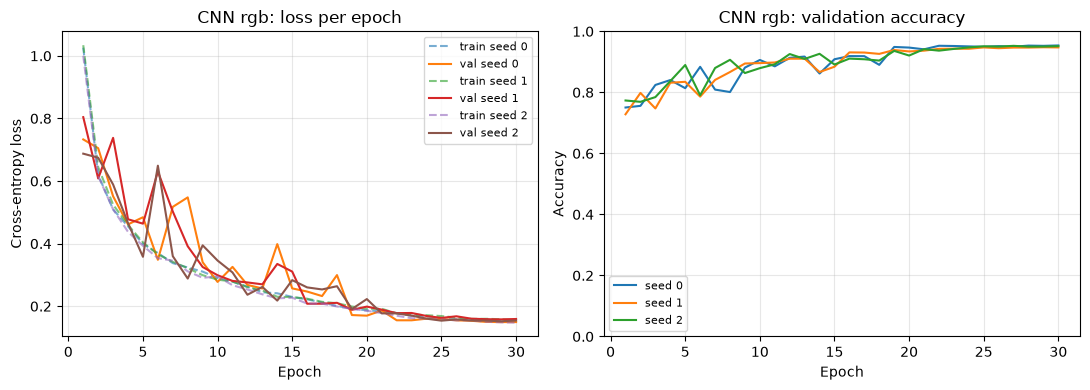

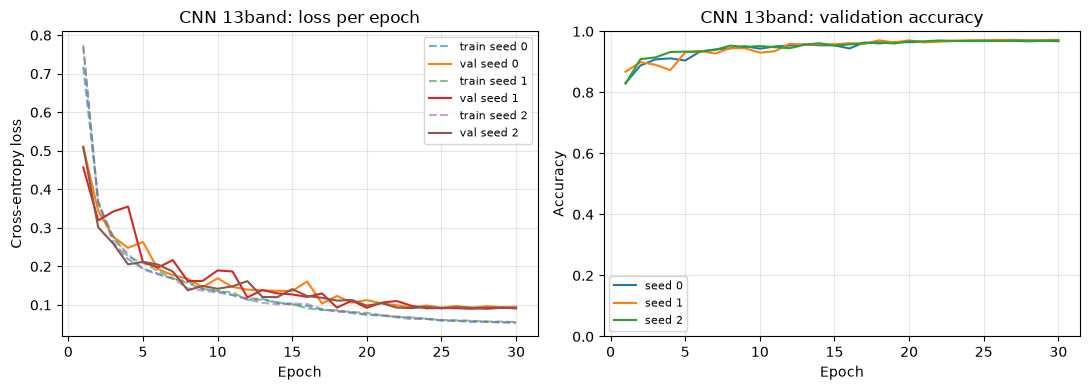

Best epoch (lowest validation loss) for each network :


,input,seed,best_epoch
2,rgb,0,29
5,rgb,1,29
8,rgb,2,29
11,13band,0,27
14,13band,1,27
17,13band,2,28


In [4]:
#plot the loss and accuracy for every epoch
for input_type in ("rgb","13band") :
    fig,axes = plt.subplots(1,2, figsize=(11,4))
    for seed in SEEDS:
        run = cnn_history[(cnn_history["input"]==input_type) & (cnn_history["seed"] == seed )]
        axes[0].plot(run["epoch"],run["train_loss"], ls="--",alpha=0.6, label=f"train seed {seed}")
        axes[0].plot(run["epoch"], run["val_loss"],label=f"val seed {seed}")
        axes[1].plot( run["epoch"], run["val_acc"], label = f"seed {seed}")

    axes[0].set(title=f"CNN {input_type}: loss per epoch",xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(title=f"CNN {input_type}: validation accuracy", xlabel="Epoch",ylabel="Accuracy", ylim=(0,1))
    for ax in axes :
        ax.grid(alpha =0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    # save figure so we can use it in the report
    fig.savefig(figures_dir/ f"cnn_{input_type}_training.png", dpi=150,bbox_inches="tight")
    plt.show()


print("Best epoch (lowest validation loss) for each network :")
display(cnn_results[cnn_results["split"].eq("test")][["input","seed","best_epoch"]])

**Claim.** Every network trained until its validation loss stopped falling, and none of them overfitted, so 30 epochs with a cosine schedule were enough.

**Reasons.** The validation loss falls steeply in the first ten epochs and is almost flat at the end, where the cosine schedule has brought the learning rate close to zero. The best epochs lie close together.

**Evidence.** Mean validation loss over the three seeds: RGB 0.742 after epoch 1, 0.308 after 10, 0.159 after 25 and 0.154 after 30; 13 bands 0.493, 0.167, 0.092 and 0.093. The best epoch is 29 for all three RGB networks and 27 or 28 for the 13-band networks. At the best epoch, the training accuracy is 95.0% (RGB) and 98.2% (13 bands), against 95.0% and 97.0% on validation.

**Warrant.** Overfitting shows as a training score far above the validation score, or a validation loss that rises again while the training loss keeps falling (lecture_2_introduction_to_ML.pdf, slide 20). Neither happens: the gap is at most 1.2 points and the validation loss changes by less than 0.006 over the last five epochs. Because the best epochs differ by at most two between seeds, the spread between seeds now measures the networks and not when training stopped, which was the problem with early stopping.

**Counterargument.** The training accuracy is measured on flipped patches while the weights are still changing, so it is only a rough check. We accept this; the changing weights most likely make the measured training score lower than the final network's, so the true gap may be somewhat larger, but it is still far from the 11-point gap of the 13-band random forest.

## 6. Results: RGB versus 13 bands

Mean and standard deviation over the three seeds, for training, validation and test. The per-class reports show seed 0 only; the other seeds are in the prediction files.

In [5]:
# mean and std over the 3 seeds
summary = cnn_results.groupby(["input","split"],sort=False)[["accuracy","macro_f1"]]
display(summary.agg(["mean", "std"]).round(4) )

#per class report, only for seed 0
for input_type in ("rgb","13band"):
    pred = pd.read_csv(predictions_dir/ f"cnn_{input_type}_seed0.csv")
    print(f"\nPer class test report : {input_type}, seed 0")
    print(classification_report(pred["y_true"],pred["y_pred"], labels=label_ids,
          target_names = list(CLASS_NAMES),zero_division=0))

accuracy         macro_f1        
                 mean     std     mean     std
input  split                                  
rgb    train   0.9500  0.0020      NaN     NaN
       val     0.9501  0.0023   0.9473  0.0026
       test    0.9177  0.0017   0.9157  0.0016
13band train   0.9823  0.0008      NaN     NaN
       val     0.9701  0.0016   0.9685  0.0018
       test    0.9539  0.0035   0.9525  0.0034


Per class test report : rgb, seed 0
                      precision    recall  f1-score   support

          AnnualCrop       0.93      0.97      0.95       429
              Forest       0.93      1.00      0.97       429
HerbaceousVegetation       0.82      0.77      0.79       428
             Highway       0.94      0.88      0.91       358
          Industrial       0.94      0.95      0.95       357
             Pasture       0.92      0.95      0.94       286
       PermanentCrop       0.79      0.82      0.81       353
         Residential       0.97      0.99      0.98       428
               River       0.93      0.86      0.89       357
             SeaLake       1.00      0.97      0.98       429

            accuracy                           0.92      3854
           macro avg       0.92      0.92      0.92      3854
        weighted avg       0.92      0.92      0.92      3854


Per class test report : 13band, seed 0
                      precision    recall  f1-score 

**Claim.** The 13 bands also improve the CNN: test accuracy rises from 91.8% to 95.4% and macro-F1 from 0.916 to 0.953, a gain far larger than the variation between seeds. The gain is smaller than for the random forest because the CNN already gets much more out of RGB.

**Reasons.** The network and the settings are the same for both inputs, apart from the first layer. The CNN sees shapes and textures in the RGB patch, which the random forest's band statistics cannot, so part of what the extra bands gave the forest the CNN already learns from RGB.

**Evidence.** Test accuracy 0.918 (RGB) against 0.954 (13 bands), macro-F1 0.916 against 0.953, each the mean of three seeds with a standard deviation of at most 0.0035. In the per-class reports (seed 0), all four agricultural classes improve: HerbaceousVegetation from an F1 of 0.79 to 0.88, PermanentCrop from 0.81 to 0.85, AnnualCrop from 0.95 to 0.97 and Pasture from 0.94 to 0.96. River gains most (0.89 to 0.98). The RGB CNN (0.918) is better than the 13-band random forest of notebook 03 (0.857).

**Warrant.** The test patches were not used for training or for choosing the best epoch (lecture_2_introduction_to_ML.pdf, slide 24). A gain of 3.6 points against a seed spread of at most 0.35 points cannot be chance. This answers SQ1 for the CNN: the 13-band advantage holds, but it shrinks from 16 points for the random forest to 3.6 points.

**Counterargument 1: validation is higher than test.** Validation is 3.3 points above test for RGB and 1.6 points for 13 bands. The best epoch was chosen on validation, but the validation loss is almost flat at the end (section 5), so the choice adds little. As in notebook 03, the rest comes from validation and test being different regions, and the drop is again smaller for 13 bands.

**Counterargument 2: one seed per class.** The per-class F1 scores are from seed 0 only. We accept this; notebook 06 uses all three seeds and the confusion matrices to show which errors the 13 bands remove.

## Summary

- A small CNN of three convolution blocks (about 95,000 weights), with 3 or 13 input channels as the only difference between the inputs.
- Training: AdamW at 0.001 with weight decay 0.0001, batch size 128, a cosine schedule over 30 epochs, and the epoch with the lowest validation loss kept.
- Every network converged (best epoch 27 to 29) and none overfitted: training and validation accuracy differ by at most 1.2 points.
- Test results (mean of 3 seeds): RGB accuracy 0.918 and macro-F1 0.916; 13 bands accuracy 0.954 and macro-F1 0.953. The seed spread is at most 0.0035.
- All four agricultural classes improve with 13 bands, HerbaceousVegetation most (F1 0.79 to 0.88). PermanentCrop remains the weakest class (0.85).
- The 13-band advantage is smaller than for the random forest (3.6 against 16 points), because the CNN already uses the shapes in RGB. Notebook 05 tests whether a pretrained ResNet changes this, and notebook 06 compares the costly errors of all models.